# Screened CSP and LDA baseline

QC retains 216 of 225 trials. With OAS covariance regularization, mean balanced accuracy is 63.1% within subjects across runs and 46.7% for a held-out subject. The original notebook used all 225 trials without screening. These results are exploratory because the data and QC thresholds have already been inspected.

In [44]:
from pathlib import Path
import sys

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the project root or notebooks directory")
sys.path.insert(0, str(PROJECT_ROOT))
from loader import get_files, load_dataset, save_qc

mne.set_log_level("WARNING")

### Load screened imagery trials

`load_dataset()` applies the fixed channel and trial QC rules in `loader.py`. The trial QC table keeps one row per original trial, including rejection reasons. This cell also updates the reports in `data/processed/qc`.

In [45]:
files = get_files()
dataset = load_dataset(files)
epochs = dataset.epochs
qc_summary = save_qc(dataset, files)

print(f"Kept {len(epochs)} of {len(dataset.trial_qc)} trials")
print(f"Interpolated channel/run pairs: {dataset.channel_qc['interpolated'].sum()}")
print(qc_summary.loc[qc_summary["review_required"]].to_string(index=False))

Kept 216 of 225 trials
Interpolated channel/run pairs: 3
 subject  run condition  total  kept  rejected  review_required
       3   12 left_hand      8     3         5             True


/Users/trentonpham/Code/eeg-motor-imagery/loader.py:229: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  mne.concatenate_epochs([result.epochs for result in results]),


## Modeling

### Prepare model inputs

`X` contains screened EEG in volts, with dimensions for trials, channels, and time samples. `y` contains the integer labels 1 and 2. `subjects` and `runs` identify the groups used to keep validation trials separate from training trials.

In [46]:
X = epochs.get_data(copy=True)
y = epochs.events[:, -1]

subjects = epochs.metadata["subject"].to_numpy()
runs = epochs.metadata["run"].to_numpy()

print("EEG array:", X.shape)
print("Labels:", np.unique(y, return_counts=True))

EEG array: (216, 64, 481)
Labels: (array([1, 2]), array([107, 109]))


In [47]:
X

array([[[-8.96284893e-06,  5.86982782e-06,  1.75244334e-05, ...,
          2.70292942e-06, -6.00094271e-06, -5.89288069e-06],
        [-1.11439008e-05,  6.84873176e-06,  1.83430864e-05, ...,
          1.39616274e-05,  2.88189437e-06, -3.37607371e-06],
        [-1.04818593e-05,  9.27099008e-06,  1.94074689e-05, ...,
          1.51956710e-05,  1.20784089e-06, -9.26841381e-06],
        ...,
        [ 1.50635350e-05,  2.63755746e-06, -1.11815096e-05, ...,
         -1.31414692e-05, -6.94636931e-07,  2.21758805e-05],
        [ 9.22414698e-06, -1.65409894e-05, -3.58724780e-05, ...,
         -2.65188881e-05, -1.41562465e-05,  1.36922814e-05],
        [ 3.10036262e-05, -6.35556433e-07, -2.27515399e-05, ...,
         -2.43391775e-05, -2.27805914e-05,  6.94153637e-06]],

       [[ 3.71658667e-06, -6.19958597e-06, -1.14683534e-05, ...,
          5.59095316e-07, -2.75964461e-06, -7.33386651e-06],
        [ 7.73813968e-06, -1.43435949e-06, -1.05099386e-05, ...,
          1.20153169e-05,  1.24020168e

In [48]:
y

array([1, 1, 2, 2, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 1, 2, 2,
       1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 1, 2, 1, 1, 2, 2, 1, 2, 1, 1, 2, 2, 1, 2, 1, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2,
       1, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2,
       2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 2, 2, 1, 2, 1, 1, 2, 1, 2, 2, 1, 2,
       1, 2, 1, 2, 2, 1, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2, 1, 1, 2, 2,
       1, 1, 2, 1, 2, 2, 1, 1, 2, 2, 2, 1, 2, 1, 1, 2, 2, 1, 1, 2, 1, 2,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 1, 2, 1, 2])

### Check class balance

QC retains 107 left-hand trials and 109 right-hand trials, for 216 total. The analysis does not oversample either class.

Subject 3, run 12 retains only 3 of 8 left-hand trials and requires review.

In [49]:
trial_table = epochs.metadata.copy()
trial_table["condition"] = np.where(
    y == 1,
    "left_hand",
    "right_hand",
)

pd.crosstab(
    trial_table["subject"],
    trial_table["condition"],
    margins=True,
)

condition,left_hand,right_hand,All
subject,,,
1,22,21,43
2,23,22,45
3,18,20,38
4,23,22,45
5,21,24,45
All,107,109,216


### Import model classes

In [50]:
from mne.decoding import CSP, get_spatial_filter_from_estimator
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score

### Build the CSP and LDA baseline

Common spatial patterns, or CSP, learns spatial filters from labeled training EEG and reduces each trial to four log-power features. Linear discriminant analysis, or LDA, classifies those features. CSP estimates OAS-regularized covariance using only the training trials in each cross-validation fold.

In [68]:
rows = []

csp = CSP(reg=0.22, log=True, norm_trace=False)
lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")

pipeline = make_pipeline(
    csp,
    lda
)

param_grid = {
    "csp__n_components": [4, 6, 8, 10, 12],
}

for train, test in LeaveOneGroupOut().split(X, y, groups=subjects):
    search = GridSearchCV(
        pipeline,
        param_grid,
        cv=LeaveOneGroupOut(),
        scoring="balanced_accuracy",
        refit=True,
        error_score="raise",
    )
    search.fit(X[train], y[train], groups=subjects[train])

    best_model = search.best_estimator_
    predictions = best_model.predict(X[test])

    rows.append({
        "subject": int(subjects[test][0]),
        "n_components": search.best_params_["csp__n_components"],
        "balanced_accuracy": balanced_accuracy_score(
            y[test], predictions
        ),
    })

results = pd.DataFrame(rows)
display(results)
print("Mean balanced accuracy:", results["balanced_accuracy"].mean())

,subject,n_components,balanced_accuracy
0,1,6,0.545455
1,2,12,0.574111
2,3,12,0.536111
3,4,12,0.500988
4,5,6,0.500000


Mean balanced accuracy: 0.5313328941589811


#### Evaluate held-out runs within each subject

For each subject, the model trains on two runs and tests on the remaining run. Each of the three runs becomes the test set once. Trial counts vary because QC removed nine trials. This measures performance across runs within a subject, not across days.

Balanced accuracy gives equal weight to left-hand and right-hand recall. The 50% chance reference is not a significance threshold.

### Means: 
#### 1) Covariance Regularization
- No covariance regularization: 0.4613
- `ledoit_wolf`: 0.4669
- `oas`: 0.4669
- `0.10`: 0.4831

#### 2) n_components
- GridSearchCV: 0.4903
- GridSearchCV + cov reg `0.20`: 0.5313



### Inspect an unregularized CSP fit on all screened trials

The following cells fit a separate, unregularized CSP model to all screened trials and plot its spatial patterns. This differs from the OAS-regularized model evaluated above. This fit is exploratory. It does not test prediction accuracy on held-out trials.

In [ ]:
lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
csp = CSP(4,reg=None, log=True, norm_trace=False)

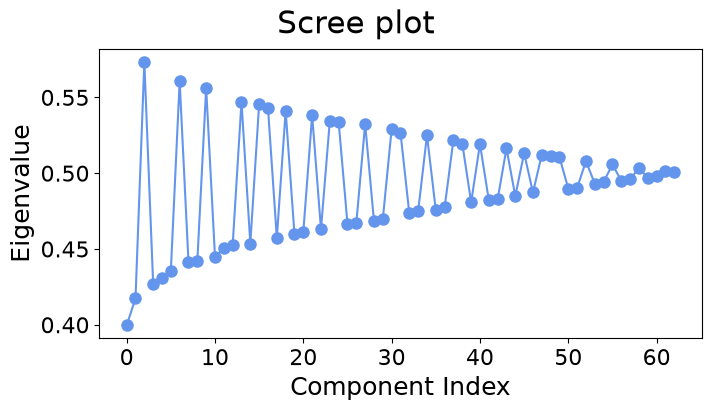

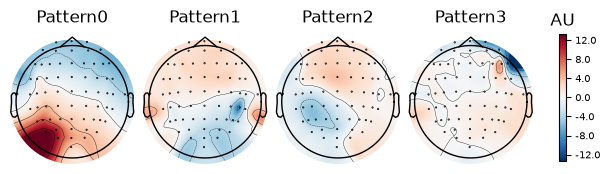

In [ ]:
csp.fit_transform(X, y)
spf = get_spatial_filter_from_estimator(csp, info=epochs.info)
spf.plot_scree()
_ = spf.plot_patterns(components=np.arange(4))

#### Interpret the CSP figures

The scree plot and scalp patterns describe the CSP fit on all screened trials. They show which spatial signals the model emphasizes, but do not validate physiological activation. The four displayed patterns correspond to the model's four CSP components.